In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import torch
from tabulate import tabulate

from umap import UMAP
from sklearn.neighbors import KNeighborsRegressor
from sklearn.cluster import DBSCAN, HDBSCAN
from sklearn.metrics import roc_auc_score, roc_curve, ConfusionMatrixDisplay, accuracy_score, auc

import load.load_dataset as ds

import warnings
warnings.filterwarnings('ignore')
import joblib

In [22]:
param_dict = joblib.load(os.path.join(os.getcwd(), "parameters.joblib"))
img_folder = os.path.join(os.getcwd(), "img", "thesis")
param_dict.pop("mnist", None)


{'n_clust': 1000}

# Prediction Accuracy

In [103]:
dataset_list = ['adult', 'bank', 'beans', 'heloc', 'ocean', 'wine'] # 'beans', 'cancer', 'mushroom',
models_list = ['model1', 'model1do1', 'model1bn' , 'model1r'] # , 'model1r'
models_colors = ['black', 'red', 'blue', 'green']

In [104]:
# test accuracy

acc_data = []
for d in dataset_list:
    dataset = ds.Dataset(d)
    _, X, y = dataset.test()
    y_true = y.argmax(dim=1).numpy()
    row = [d]
    for m in models_list:
        model = dataset.load_model(m)
        model.eval()
        with torch.no_grad():
            preds = model(X).argmax(dim=1).numpy()
        row.append(accuracy_score(y_true, preds))
    acc_data.append(row)

print('Test accuracy')
print(tabulate(acc_data, headers=["Dataset", *models_list], tablefmt="github", floatfmt=".4f"))

Test accuracy
| Dataset   |   model1 |   model1do1 |   model1bn |   model1r |
|-----------|----------|-------------|------------|-----------|
| adult     |   0.8360 |      0.8370 |     0.8250 |    0.8380 |
| bank      |   0.9080 |      0.9050 |     0.9140 |    0.9140 |
| beans     |   0.9120 |      0.9140 |     0.9120 |    0.9080 |
| heloc     |   0.7260 |      0.7140 |     0.6780 |    0.7060 |
| ocean     |   0.8298 |      0.8314 |     0.7749 |    0.7963 |
| wine      |   0.8550 |      0.8550 |     0.8650 |    0.8850 |


# Prediction AUC

In [105]:
def ovr_roc(y_onehot, proba):
    if proba.shape[1] == 2:
        y, p = y_onehot[:, 1], proba[:, 1]
    else:
        y, p = y_onehot.ravel(), proba.ravel()
    fpr, tpr, _ = roc_curve(y, p)
    return roc_auc_score(y, p), fpr, tpr

def plot_roc(y_val, results, dataset_name, models_colors, models_list):
    y_onehot = y_val.detach().numpy()
    auc_scores = []

    plt.figure()
    plt.title(dataset_name)
    for i in range(len(results)):
        roc, fpr, tpr = ovr_roc(y_onehot, results[i]['pred_proba'][0])
        plt.plot(fpr, tpr, color=models_colors[i], label=f'{models_list[i]} - {roc:.4f}')
        auc_scores.append(roc)

    plt.plot([0,1],[0,1], color='grey', linestyle='--', label='Random')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend()

    plt.tight_layout()
    plt.show()

    return auc_scores

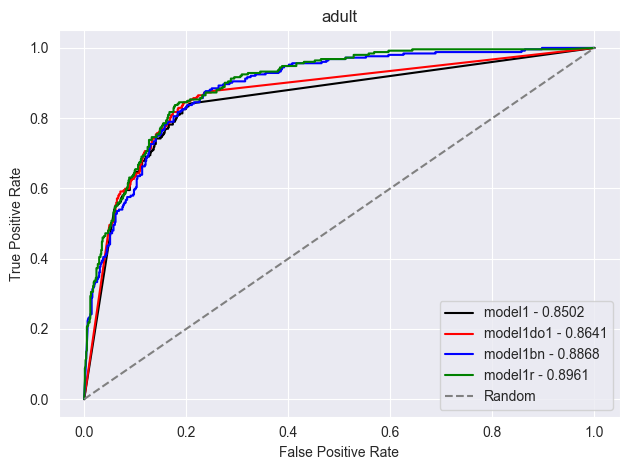

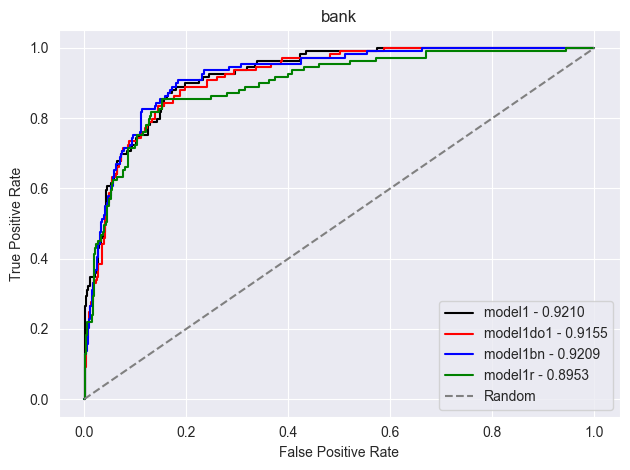

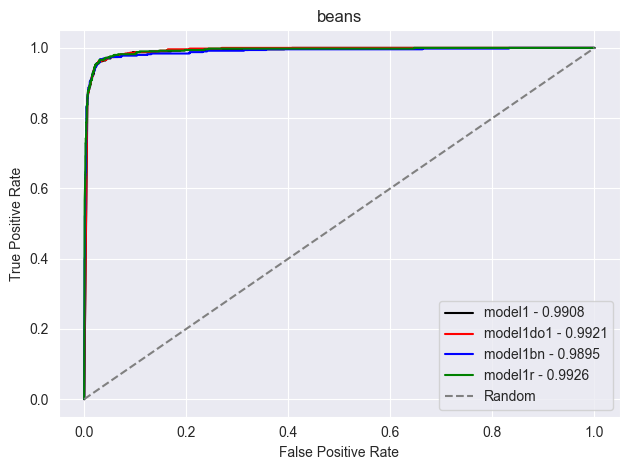

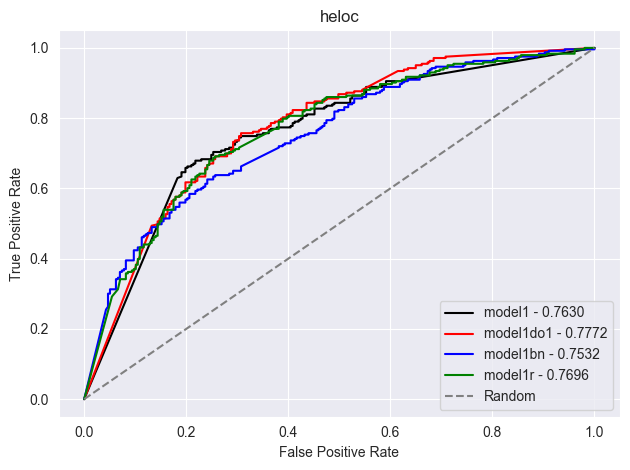

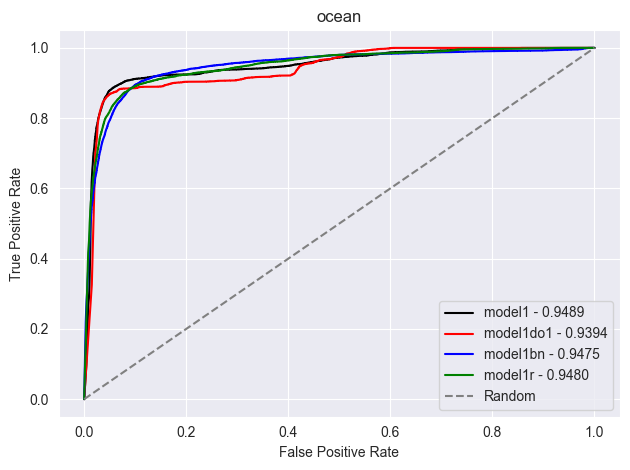

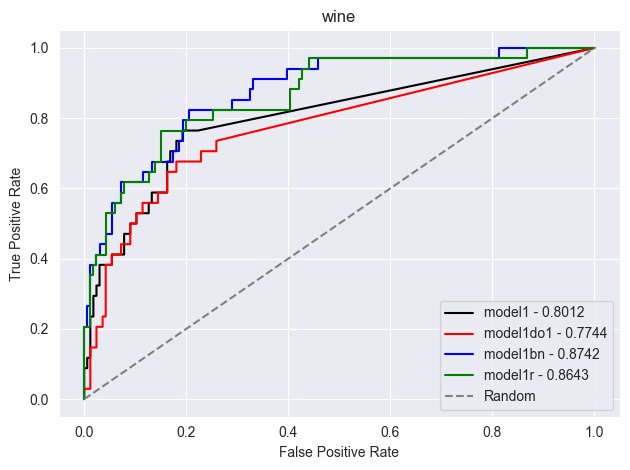

Test AUC
| Dataset   |   model1 |   model1do1 |   model1bn |   model1r |
|-----------|----------|-------------|------------|-----------|
| adult     |   0.8502 |      0.8641 |     0.8868 |    0.8961 |
| bank      |   0.9210 |      0.9155 |     0.9209 |    0.8953 |
| beans     |   0.9908 |      0.9921 |     0.9895 |    0.9926 |
| heloc     |   0.7630 |      0.7772 |     0.7532 |    0.7696 |
| ocean     |   0.9489 |      0.9394 |     0.9475 |    0.9480 |
| wine      |   0.8012 |      0.7744 |     0.8742 |    0.8643 |


In [106]:
# test AUCs

auc_data = []
for d in dataset_list:
    dataset = ds.Dataset(d)
    _, X, y = dataset.test()
    y_onehot = y.numpy()
    row = [d]
    probas = []
    for m in models_list:
        model = dataset.load_model(m)
        model.eval()
        with torch.no_grad():
            proba = model(X).numpy()
        probas.append(proba)
        auc, _, _ = ovr_roc(y_onehot, proba)
        row.append(auc)
    auc_data.append(row)

    plot_roc(y, [{'pred_proba': [p]} for p in probas], d, models_colors, models_list)

print('Test AUC')
print(tabulate(auc_data, headers=["Dataset", *models_list], tablefmt="github", floatfmt=".4f"))

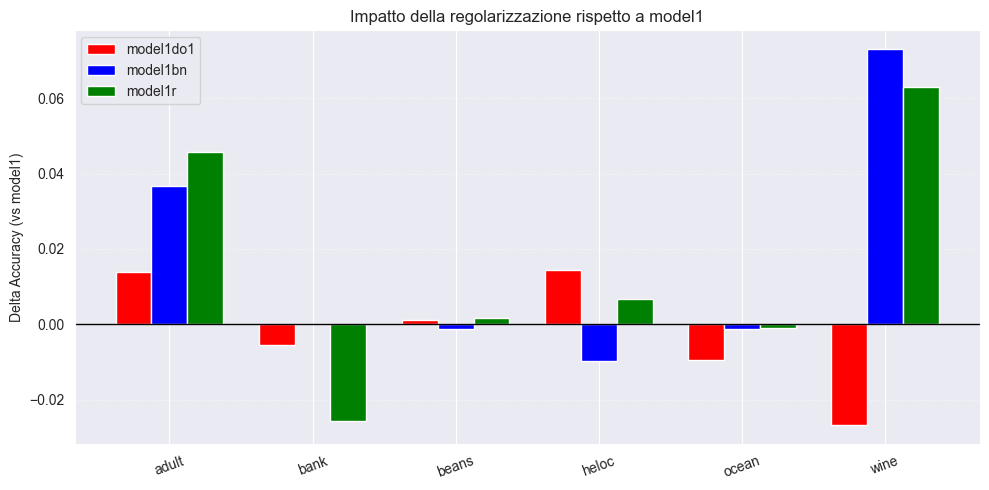

In [107]:
headers = ["Dataset", "model1", "model1do1", "model1bn", "model1r"]

df = pd.DataFrame(auc_data, columns=headers)

reg_cols = models_list[1:]
baseline = models_list[0]
delta = df[reg_cols].sub(df[baseline], axis=0)
delta.index = df["Dataset"]

x = np.arange(len(delta.index))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
for i, col in enumerate(reg_cols):
  ax.bar(x + (i - 1) * width, delta[col], width, label=col, color=models_colors[i+1])

ax.axhline(0, color="black", linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(delta.index, rotation=20)
ax.set_ylabel("Delta Accuracy (vs model1)")
ax.set_title("Impatto della regolarizzazione rispetto a model1")
ax.grid(axis="y", linestyle=":", alpha=0.6)
ax.legend()

plt.tight_layout()
plt.show()

# Regularization general: effect on robustness

Dropout slightly improve, BN worsen robustness


In [23]:
df_ens = pd.read_excel(os.path.join(os.getcwd(), "results_roc_auc", "my_originals", "ensemble_medoid_threshold.xlsx"))
df_do = pd.read_excel(os.path.join(os.getcwd(), "results_roc_auc", "ensemble_medoid_threshold_do1.xlsx"))
df_bn = pd.read_excel(os.path.join(os.getcwd(), "results_roc_auc", "ensemble_medoid_threshold_bn.xlsx"))
df_r = pd.read_excel(os.path.join(os.getcwd(), "results_roc_auc", "ensemble_medoid_threshold_reg.xlsx"))

df_ens_random = pd.read_excel(os.path.join(os.getcwd(), "results_roc_auc", "my_originals", "ensemble_random_threshold.xlsx"))
df_do_random = pd.read_excel(os.path.join(os.getcwd(), "results_roc_auc", "ensemble_random_threshold_do1.xlsx"))
df_bn_random = pd.read_excel(os.path.join(os.getcwd(), "results_roc_auc", "ensemble_random_threshold_bn.xlsx"))
df_r_random = pd.read_excel(os.path.join(os.getcwd(), "results_roc_auc", "ensemble_random_threshold_reg.xlsx"))

#df_ens_random = pd.read_excel(os.path.join(os.getcwd(), "results_roc_auc", "ensemble_random_threshold_bn.xlsx"))
#df_mean_random = pd.read_excel(os.path.join(os.getcwd(), "results_roc_auc", "mean_random_threshold_bn.xlsx"))

param_dict = joblib.load(os.path.join(os.getcwd(), "parameters.joblib"))
param_dict.pop("mnist", None)

{'n_clust': 1000}

In [24]:
# Table 1 ensemble

th = 0.80

model_name = "model1"
df_e_t1 = df_ens[np.isclose(df_ens["threshold"], th) & df_ens["model"].isin([model_name])].copy()
df_e_t1["rob_%"] = 100 * df_e_t1["robust"] / df_e_t1["len"]
df_e_t1["maybe_%"] = 100 * df_e_t1["maybe"] / df_e_t1["len"]
df_e_t1["non_rob_%"] = 100 * df_e_t1["non robust"] / df_e_t1["len"]
df_e_t1 = df_e_t1.set_index("dataset")[["rob_%", "maybe_%", "non_rob_%"]]

model_do = f"{model_name}do1"
df_do_t1 = df_do[np.isclose(df_do["threshold"], th) & df_do["model"].isin([model_do])].copy()
df_do_t1["rob_%"] = 100 * df_do_t1["robust"] / df_do_t1["len"]
df_do_t1["maybe_%"] = 100 * df_do_t1["maybe"] / df_do_t1["len"]
df_do_t1["non_rob_%"] = 100 * df_do_t1["non robust"] / df_do_t1["len"]
df_do_t1 = df_do_t1.set_index("dataset")[["rob_%", "maybe_%", "non_rob_%"]]

model_bn = f"{model_name}bn"
df_bn_t1 = df_bn[np.isclose(df_bn["threshold"], th) & df_bn["model"].isin([model_bn])].copy()
df_bn_t1["rob_%"] = 100 * df_bn_t1["robust"] / df_bn_t1["len"]
df_bn_t1["maybe_%"] = 100 * df_bn_t1["maybe"] / df_bn_t1["len"]
df_bn_t1["non_rob_%"] = 100 * df_bn_t1["non robust"] / df_bn_t1["len"]
df_bn_t1 = df_bn_t1.set_index("dataset")[["rob_%", "maybe_%", "non_rob_%"]]


table1 = df_do_t1.join(df_e_t1, lsuffix="_ens", rsuffix="_mean").join(df_bn_t1, lsuffix="_ens", rsuffix="_mean")
table1 = table1.round(1)

table1.columns = pd.MultiIndex.from_tuples([
    ("Dropout", "Robust"),
    ("Dropout", "Uncertain"),
    ("Dropout", "Non Robust"),
    (model_name, "Robust"),
    (model_name, "Uncertain"),
    (model_name, "Non Robust"),
    ("BatchNorm", "Robust"),
    ("BatchNorm", "Uncertain"),
    ("BatchNorm", "Non Robust"),
])

table1 = table1.reindex([d for d in param_dict.keys() if d in table1.index])
table1.index.name = None
table1.columns.names = [None, None]
display(table1)

Dropout                      model1                      BatchNorm  \
          Robust Uncertain Non Robust Robust Uncertain Non Robust    Robust   
adult       79.3       4.1       16.6   73.2       5.5       21.3      18.5   
bank        69.5       6.5       24.0   67.0       6.6       26.4       5.6   
beans       77.8       4.8       17.4   75.6       6.2       18.2      95.6   
cancer      72.0       6.0       22.0   78.0       4.0       18.0      48.0   
heloc       13.8      17.4       68.8   26.4      22.8       50.8      12.2   
mushroom    26.0       6.8       67.2    8.0       3.0       89.0       4.8   
ocean       79.4       5.8       14.8   76.8       5.8       17.4      83.9   
wine         3.5      29.5       67.0    2.0      20.0       78.0       7.5   

                               
         Uncertain Non Robust  
adult         21.6       59.9  
bank          16.1       78.3  
beans          0.2        4.2  
cancer        18.0       34.0  
heloc         24.0       63.8  
mushroom       5.0       90.2  
ocean          3.4       12.7  
wine          32.5       60.0

In [25]:
# Table 1 ma solo robust, threshold per dataset

th_key = "ensemble_medoid_th"
th_map = {ds: p[th_key] for ds, p in param_dict.items() if th_key in p}

def rob_pct(df, model):
    d = df[(df["model"] == model) & df["dataset"].isin(th_map)].copy()
    d = d[np.isclose(d["threshold"], d["dataset"].map(th_map))]
    return (100 * d["robust"] / d["len"]).set_axis(d["dataset"])

model_name = "model1"
table1 = pd.concat({
    (model_name, "Robust"): rob_pct(df_ens, model_name),
    ("Dropout", "Robust"): rob_pct(df_do, f"{model_name}do1"),
    ("BatchNorm", "Robust"): rob_pct(df_bn, f"{model_name}bn"),
    ("BN+Dropout", "Robust"): rob_pct(df_r, f"{model_name}r"),
}, axis=1).round(1)

table1 = table1.reindex([d for d in param_dict.keys() if d in table1.index])
average = ((table1[("Dropout", "Robust")] + table1[("BatchNorm", "Robust")]) / 2).round(1)

display(table1)
print(average)

,model1,Dropout,BatchNorm,BN+Dropout
,Robust,Robust,Robust,Robust
dataset,,,,
adult,73.2,79.3,18.5,57.7
bank,67.0,69.5,5.6,22.5
beans,67.4,68.0,88.6,90.2
cancer,58.0,40.0,34.0,48.0
heloc,26.4,13.8,12.2,25.4
mushroom,78.0,94.8,86.2,82.5
ocean,95.8,94.3,97.9,97.7
wine,0.5,0.5,3.0,6.0


dataset
adult       48.9
bank        37.6
beans       78.3
cancer      37.0
heloc       13.0
mushroom    90.5
ocean       96.1
wine         1.8
dtype: float64


In [112]:
# Table 1 ma solo robust, threshold fisso

th = 0.80

model_name = "model1"
df_e_t1 = df_ens[np.isclose(df_ens["threshold"], th) & df_ens["model"].isin([model_name])].copy()
df_e_t1["rob_%"] = 100 * df_e_t1["robust"] / df_e_t1["len"]
df_e_t1 = df_e_t1.set_index("dataset")[["rob_%"]]

model_do = f"{model_name}do1"
df_do_t1 = df_do[np.isclose(df_do["threshold"], th) & df_do["model"].isin([model_do])].copy()
df_do_t1["rob_%"] = 100 * df_do_t1["robust"] / df_do_t1["len"]
df_do_t1 = df_do_t1.set_index("dataset")[["rob_%"]]

model_bn = f"{model_name}bn"
df_bn_t1 = df_bn[np.isclose(df_bn["threshold"], th) & df_bn["model"].isin([model_bn])].copy()
df_bn_t1["rob_%"] = 100 * df_bn_t1["robust"] / df_bn_t1["len"]
df_bn_t1 = df_bn_t1.set_index("dataset")[["rob_%"]]

model_r = f"{model_name}r"
df_r_t1 = df_r[np.isclose(df_r["threshold"], th) & df_r["model"].isin([model_r])].copy()
df_r_t1["rob_%"] = 100 * df_r_t1["robust"] / df_r_t1["len"]
df_r_t1 = df_r_t1.set_index("dataset")[["rob_%"]]

average = [(df_do_t1+df_bn_t1)/2]


table1 = (
    df_e_t1
    .join(df_do_t1, lsuffix="_a", rsuffix="_b")
    .join(df_bn_t1, lsuffix="_c", rsuffix="_d")
    .join(df_r_t1, lsuffix="_e", rsuffix="_f")
)
table1 = table1.round(1)

table1.columns = pd.MultiIndex.from_tuples([
    (model_name, "Robust"),
    ("Dropout", "Robust"),
    ("BatchNorm", "Robust"),
    ("BN+Dropout", "Robust"),
])

table1 = table1.reindex([d for d in param_dict.keys() if d in table1.index])
table1.index.name = None
table1.columns.names = [None, None]
display(table1)

print(average)

,model1,Dropout,BatchNorm,BN+Dropout
,Robust,Robust,Robust,Robust
adult,73.2,79.3,18.5,57.7
bank,67.0,69.5,5.6,22.5
beans,75.6,77.8,95.6,97.4
cancer,78.0,72.0,48.0,64.0
heloc,26.4,13.8,12.2,25.4
mushroom,8.0,26.0,4.8,19.0
ocean,76.8,79.4,83.9,86.8
wine,2.0,3.5,7.5,29.0


[           rob_%
dataset         
adult     48.900
bank      37.550
beans     86.700
cancer    60.000
heloc     13.000
mushroom  15.375
ocean     81.620
wine       5.500]


In [114]:
# Table 1 ma solo robust, threshold fisso, PER OFF MANIFOLD RANDOM NEIGHBOUR

th = 0.80

model_name = "model1"
df_e_t1 = df_ens_random[np.isclose(df_ens["threshold"], th) & df_ens["model"].isin([model_name])].copy()
df_e_t1["rob_%"] = 100 * df_e_t1["robust"] / df_e_t1["len"]
df_e_t1 = df_e_t1.set_index("dataset")[["rob_%"]]

model_do = f"{model_name}do1"
df_do_t1 = df_do_random[np.isclose(df_do["threshold"], th) & df_do["model"].isin([model_do])].copy()
df_do_t1["rob_%"] = 100 * df_do_t1["robust"] / df_do_t1["len"]
df_do_t1 = df_do_t1.set_index("dataset")[["rob_%"]]

model_bn = f"{model_name}bn"
df_bn_t1 = df_bn_random[np.isclose(df_bn["threshold"], th) & df_bn["model"].isin([model_bn])].copy()
df_bn_t1["rob_%"] = 100 * df_bn_t1["robust"] / df_bn_t1["len"]
df_bn_t1 = df_bn_t1.set_index("dataset")[["rob_%"]]

model_r = f"{model_name}r"
df_r_t1 = df_r_random[np.isclose(df_r["threshold"], th) & df_r["model"].isin([model_r])].copy()
df_r_t1["rob_%"] = 100 * df_r_t1["robust"] / df_r_t1["len"]
df_r_t1 = df_r_t1.set_index("dataset")[["rob_%"]]

average = [(df_do_t1+df_bn_t1)/2]


table1 = (
    df_e_t1
    .join(df_do_t1, lsuffix="_a", rsuffix="_b")
    .join(df_bn_t1, lsuffix="_c", rsuffix="_d")
    .join(df_r_t1, lsuffix="_e", rsuffix="_f")
)
table1 = table1.round(1)

table1.columns = pd.MultiIndex.from_tuples([
    (model_name, "Robust"),
    ("Dropout", "Robust"),
    ("BatchNorm", "Robust"),
    ("BN+Dropout", "Robust"),
])

table1 = table1.reindex([d for d in param_dict.keys() if d in table1.index])
table1.index.name = None
table1.columns.names = [None, None]
display(table1)

print(average)

,model1,Dropout,BatchNorm,BN+Dropout
,Robust,Robust,Robust,Robust
adult,9.1,9.5,0.1,1.1
bank,11.0,13.4,0.6,2.1
beans,48.0,52.6,23.6,23.0
cancer,6.0,14.0,0.0,0.0
heloc,0.0,0.0,0.0,0.0
mushroom,0.0,6.8,3.5,2.5
ocean,46.7,60.2,47.3,63.1
wine,0.0,0.0,1.0,0.0


[           rob_%
dataset         
adult      4.800
bank       7.000
beans     38.100
cancer     7.000
heloc      0.000
mushroom   5.125
ocean     53.735
wine       0.500]


In [14]:
files = {"model1": "my_originals/ensemble_medoid_threshold.xlsx",
         "model1do1": "ensemble_medoid_threshold_do1.xlsx",
         "model1bn": "ensemble_medoid_threshold_bn.xlsx",
         "model1r": "ensemble_medoid_threshold_reg.xlsx"
         }

model_name = {}
for mod, f in files.items():
    df = pd.read_excel(os.path.join(os.getcwd(), "results_roc_auc", f))
    d = df[np.isclose(df["threshold"], 0.75) & (df["model"] == mod)].set_index("dataset")
    model_name[mod] = [100 * d["robust concordant"] / d["tot robust"],
                       100 * d["non robust concordant"] / d["tot non robust"]]

table2_cmp = pd.concat({(grp, mod): model_name[mod][j]
                        for j, grp in enumerate(["Robust Agree", "Non Robust Agree"])
                        for mod in model_name}, axis=1).round(1)
display(table2_cmp)

Robust Agree                            Non Robust Agree            \
               model1 model1do1 model1bn model1r           model1 model1do1   
dataset                                                                       
adult            93.0      91.9     89.4    91.3             64.1      61.1   
bank             95.7      92.4     93.1    91.8             78.9      74.3   
beans            92.9      91.5     96.3    92.7            100.0      90.6   
cancer           95.6      90.9     92.1    93.2            100.0     100.0   
heloc            82.2      78.9     76.4    76.3             57.3      78.3   
mushroom        100.0     100.0    100.0   100.0            100.0     100.0   
ocean            68.9      70.5     79.2    75.2             74.2      75.3   
wine             87.1      90.7     82.0    87.5             93.8      93.2   

                           
         model1bn model1r  
dataset                    
adult        92.0    87.1  
bank         95.8    94.5  
beans       100.0    80.0  
cancer       91.7   100.0  
heloc        77.8    72.2  
mushroom    100.0   100.0  
ocean        71.4    71.2  
wine         85.9    72.9

In [26]:
# only model 1s
#atasets = [ds for ds in param_dict if ds != "mnist"]

files = {"model1": "my_originals/ensemble_medoid_threshold.xlsx",
         "model1do1": "ensemble_medoid_threshold_do1.xlsx",
         "model1bn": "ensemble_medoid_threshold_bn.xlsx",
         "model1r": "ensemble_medoid_threshold_reg.xlsx"}

auc_dict = {}
for mod, f in files.items():
    df = pd.read_excel(os.path.join(os.getcwd(), "results_roc_auc", f))
    d = df[df["model"] == mod]
    tpr = (d["robust concordant"] / (d["robust concordant"] + d["non robust concordant"])).fillna(0)
    fpr = (d["robust discordant"] / (d["robust discordant"] + d["non robust discordant"])).fillna(0)
    auc_dict[mod] = {ds: auc(fpr[d["dataset"] == ds].values[::-1], tpr[d["dataset"] == ds].values[::-1])
                     for ds in param_dict.keys()}

table_auc = (100 * pd.DataFrame(auc_dict)).round(2)
table_auc.index.name = "Dataset"
display(table_auc)

,model1,model1do1,model1bn,model1r
Dataset,,,,
adult,73.88,76.43,42.89,48.86
bank,76.75,69.22,44.89,39.36
beans,53.65,66.66,52.97,71.40
cancer,27.08,58.70,46.47,38.65
heloc,68.21,50.86,48.32,52.40
mushroom,0.00,0.00,0.00,0.00
ocean,45.88,52.88,57.60,58.39
wine,34.76,38.04,46.18,62.20


In [27]:
# AVERAGE over models 1 2 3
sets = {"SmallNN": ("my_originals/ensemble_medoid_threshold.xlsx", ["model1", "model2", "model3"]),
        "Dropout": ("ensemble_medoid_threshold_do1.xlsx", ["model1do1", "model2do1", "model3do1"]),
        "BatchNorm": ("ensemble_medoid_threshold_bn.xlsx", ["model1bn", "model2bn", "model3bn"]),
        "BN+Dropout": ("ensemble_medoid_threshold_reg.xlsx", ["model1r", "model2r", "model3r"])}

auc_dict = {}
for col, (f, models) in sets.items():
    df = pd.read_excel(os.path.join(os.getcwd(), "results_roc_auc", f))
    tpr = (df["robust concordant"] / (df["robust concordant"] + df["non robust concordant"])).fillna(0)
    fpr = (df["robust discordant"] / (df["robust discordant"] + df["non robust discordant"])).fillna(0)
    auc_dict[col] = {ds: np.mean([auc(fpr[(df["dataset"] == ds) & (df["model"] == m)].values[::-1],
                                      tpr[(df["dataset"] == ds) & (df["model"] == m)].values[::-1])
                                  for m in models])
                     for ds in param_dict.keys()}

table_auc = (100 * pd.DataFrame(auc_dict)).round(2)
table_auc.index.name = "Dataset"
display(table_auc)

,SmallNN,Dropout,BatchNorm,BN+Dropout
Dataset,,,,
adult,70.02,76.06,50.37,48.14
bank,72.02,67.69,41.16,39.92
beans,56.93,63.62,56.47,64.92
cancer,63.89,62.14,58.79,49.76
heloc,58.36,51.02,46.21,55.25
mushroom,0.00,0.00,0.00,0.00
ocean,47.61,54.82,55.86,56.48
wine,42.58,50.88,47.43,54.09


# Dataset specific plots

- bank robustness worsen with BN, show attribution vector of bank
- regularization worsen heloc robustness, understand why
- regularization improve wine robustness, understand why

#### adult

#### bank

we can see how adding BN in bank reduce the robustness score, upon further analysis it can be seen that the attribution vectors of regularized models of bank have a lower variance compared to the non regularized models. <br><br>
HYPOTHESIS: this is because the regularization move the decision boundary of the model toward a space where smaller variation and noise count against the correct prediction, MAYBE BECAUSE BANK IS A DATASET WHERE A MORE OVERFITTED DECISION BOUNDARY MAKES BETTER PREDICTIONS

In [98]:
model_list = ['model1','model2','model3']
dataset_name = "bank"

neigh = "medoid" # medoid random
set_type = "test" # validation test

folder = os.path.join(os.getcwd(), f"results_{neigh}")

def compute_variances(folder, model_name, compare_with, dataset_name, set_type):
    variance_vec = []

    folder_ = os.path.join(folder, f"{dataset_name}_{model_name}")
    folder_reg = os.path.join(folder, f"{dataset_name}_{model_name}{compare_with}")

    # FOR ENSEMBLE
    """att_m = np.load(os.path.join(folder_, f"{set_type}", "ensemble.npy"))
    att_reg = np.load(os.path.join(folder_reg, f"{set_type}", "ensemble.npy"))
    att_m = att_m[:, 0, :]
    att_reg = att_reg[:, 0, :]"""

    # FOR SINGLE METHOD ATTRIBUTIONS
    # 0:IG, 1:DL, 2:LRP
    att_m = np.load(os.path.join(folder_, f"{set_type}", "attributions.npy"))
    att_reg = np.load(os.path.join(folder_reg, f"{set_type}", "attributions.npy"))
    att_m = att_m[:, 0, :, 1]
    att_reg = att_reg[:, 0, :, 1]

    att_m = np.abs(att_m)
    att_m = att_m / att_m.sum(axis=1, keepdims=True)
    variance_m = att_m.var(axis=1)

    att_reg = np.abs(att_reg)
    att_reg = att_reg / att_reg.sum(axis=1, keepdims=True)
    variance_reg = att_reg.var(axis=1)

    variance_vec.append([variance_m, variance_reg])
    return np.array(variance_vec).squeeze()

In [ ]:
model_names_disp = ["SmallNN", "DeeperNN", "ShallowNN"]
fig, axes = plt.subplots(1, 3, figsize=(12, 5), sharey=True)
for idx, model_name in enumerate(model_list):
    ax = axes[idx]

    variance_m, variance_bn = compute_variances(folder, model_name, 'bn', dataset_name, set_type)
    sns.histplot(variance_m, ax = ax, kde=True, stat="density", bins=100, label=model_names_disp[idx])
    sns.histplot(variance_bn, ax = ax, kde=True, stat="density", bins=100, label="BatchNorm")

    #ax.hist(variance_bn, bins=100, alpha=0.5, label="BatchNorm", color="blue")
    # ax.hist(variance_m, bins=100, alpha=0.5, label=model_names_disp[idx], color="black")
    ax.set_xlabel("Variance")
    ax.set_title(model_names_disp[idx])
    ax.legend()

fig.suptitle("Variances of attribution vectors, bank dataset", fontsize=14)
plt.tight_layout()
img_folder = os.path.join(os.getcwd(), "img", "thesis", f"bank_variance.png")
plt.savefig(img_folder, dpi=300, bbox_inches="tight")
plt.show()

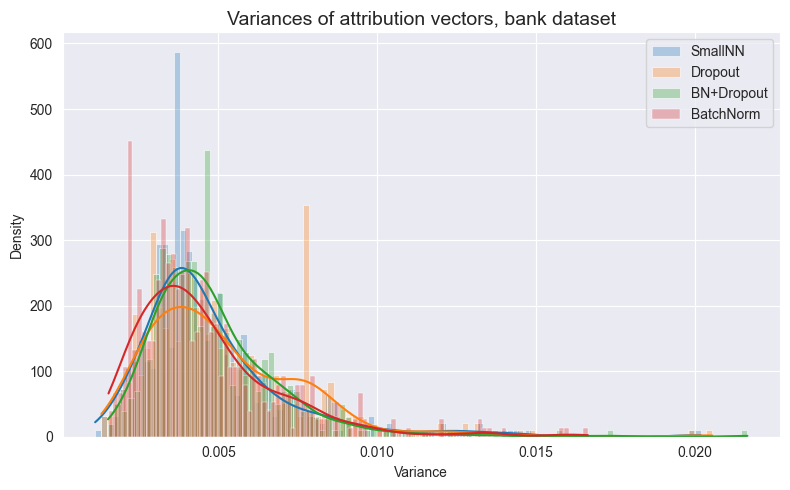

In [99]:
model_name = "model1"
dataset_name = "heloc"

variance_m, variance_bn = compute_variances(folder, model_name, 'bn', dataset_name, set_type)
_, variance_do = compute_variances(folder, model_name, 'do1', dataset_name, set_type)
_, variance_r = compute_variances(folder, model_name, 'r', dataset_name, set_type)

fig, ax = plt.subplots(figsize=(8, 5))
for data, label in [(variance_m, "SmallNN"), (variance_do, "Dropout"),
                    (variance_r, "BN+Dropout"), (variance_bn, "BatchNorm")]:
    sns.histplot(data, ax=ax, kde=True, stat="density", bins=100, alpha=0.3, label=label)

ax.set_xlabel("Variance")
ax.set_title("Variances of attribution vectors, bank dataset", fontsize=14)
ax.legend()
fig.tight_layout()
plt.show()

#### heloc

#### ocean

# MAPPA cambiamento

In [ ]:
def plot_map(dataset_name, model_name, neigh = "medoid", agg = "ensemble"):
    folder = os.path.join(os.getcwd(), f"results_{neigh}")
    dataset = ds.Dataset(dataset_name)
    X_val_or, X_val, y_val = dataset.validation()
    X_test_or, X_test, y_test = dataset.test()

    th = 0.80
    k_r = param_dict[dataset_name][f"{agg}_{neigh}_k"]

    folder_ = os.path.join(folder, f"{dataset_name}_{model_name}")
    rho_valid = np.nan_to_num(np.load(os.path.join(folder_, "validation", f"robustness_{agg}_{neigh}.npy")))
    rho_test = np.load(os.path.join(folder_, "test", f"robustness_{agg}_{neigh}.npy"))

    rob_hat = KNeighborsRegressor(n_neighbors=k_r).fit(X_val_or, rho_valid[:,3]).predict(X_test_or)
    rob_ = rho_test[:,3]

    labels = np.full(len(rob_), "Non Robust", dtype=object)
    labels[(rob_ >= th) & (rob_hat < th)] = "Uncertain"
    labels[(rob_ >= th) & (rob_hat >= th)] = "Robust"

    umap = UMAP(n_components=2, random_state=0, n_jobs=1)
    X_new = umap.fit_transform(X_test_or)

    palette = {"Robust": "tab:blue", "Uncertain": "tab:green", "Non Robust": "tab:orange"}

    plt.figure(figsize=(8,6))
    for lab, col in palette.items():
        m = labels == lab
        plt.scatter(X_new[m,0], X_new[m,1], c=col, s=50, label=f"{lab} ({100*m.mean():.1f}%)")
    plt.title(f"UMAP projections Robustness coloring: {dataset_name} {model_name} ({agg} {neigh})")
    plt.xlabel("$P_1$")
    plt.ylabel("$P_2$")
    plt.legend()
    plt.show()

In [ ]:
dataset_name = "ocean"
plot_map(dataset_name, "model1")
plot_map(dataset_name, "model1do1")
plot_map(dataset_name, "model1bn")
plot_map(dataset_name, "model1r")

# prod